# Milestone 2 — Hierarchical Parsing and Standardization

**HCMUS | Introduction to Data Science | NAME: THIỀU QUANG | ID: 24127114**

This page **continues after the completion of Milestone 1** with an offline parser of the original TeX/BibTeX source corpus. Values, tables and figures below are computed from actual `report_data/milestone2_*.{json,csv}` at book compilation, not images or fabricated benchmark statistics.

**Assigned range:** 2607.13694–2607.18693. Always report processed count alongside coverage rates; a partial prefix is not full coverage.


## Dataset coverage and completion status

**Milestone 1:** 5,000 discovered publications
out of 5,000 assigned IDs.

**Milestone 2:** All 5,000 assigned publications processed;
6,417 versions in total;
6,105 parsed;
312 empty;
0 without a detected root.

**Completion status:** The full assigned range was processed, covering
5,000 of 5,000 publications.


## 1. Architecture and multi-file gathering

`src.milestone2.pipeline.Milestone2Parser` inherits `Milestone1CorpusReader`, which **reuses the existing `src.crawler.paper_dir()` and `read_json()`**. The new `Milestone2MemorySampler` also inherits `src.crawler.MemorySampler`, calling `super().finish()`. No code or original data in Milestone 1 is rewritten.

For every `vN`, locate the active `.tex` file containing an uncommented `\documentclass`, expand uncommented `\input` / `\include` commands recursively, reject traversal outside the source folder, stop at `\end{document}`, and ignore unreachable auxiliary TeX files. Document headings create parent/child relations, while sentences, displayed mathematics, figures and tables are leaves. Nested lists create `list` → `item` branches. References are excluded from the content tree. Acknowledgements and unnumbered appendix sections remain in the tree.

**Known limits:** LaTeX is a macro language; without invoking TeX, dynamically generated includes, conditionals, style-file macro expansions, `\includeonly` variants and complex custom bibliography macros cannot always be resolved. Such papers should be sampled for manual comparison with a compiled PDF.


## 2. Cleaning, normalization, citations and identity

Comment-only includes are ignored. Nonsemantic formatting commands and whitespace are cleaned without changing the Milestone 1 `.tex` sources. Inline `\(…\)` / `\begin{math}` becomes `$…$`; displayed `\[…\]`, `$$…$$`, and display math environments become a uniform `\begin{equation}…\end{equation}` leaf. Sentence boundaries conservatively protect common abbreviations, math, decimals, URLs and command arguments.

BibTeX files requested by the compilation path and inline `\bibitem` entries are parsed into a consistent entry schema. Across versions, matching DOI/title entries share one canonical citation key; available metadata fields are unioned, and `\cite{}` keys are rewritten in the **parsed output only**. Cleaned content identical across versions shares one element ID, while `hierarchy` carries a version-specific parent edge. Each version keeps an explicit outcome, including `empty` for legitimate no-source and `no_root` for detected parsing limitations.

For each publication, the pipeline writes per-paper checkpoints and JSONL tables `elements`, `hierarchy`, `bibtex`, plus `versions` for root IDs and error/coverage inspection.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

report_data = Path('report_data')
summary_path = report_data / 'milestone2_summary.json'
status_path = report_data / 'milestone2_status.csv'
benchmark_path = report_data / 'milestone2_benchmark_history.json'
benchmark = json.loads(benchmark_path.read_text(encoding='utf-8')) if benchmark_path.exists() else {}
ready = summary_path.is_file() and status_path.is_file()
if ready:
    stats = json.loads(summary_path.read_text(encoding='utf-8'))
    counts = stats.get('metrics', {})
    rows = pd.read_csv(status_path)
    display(Markdown(f"**Measured sample: {stats['assigned_count_this_run']:,} publications** "
                     f"({stats.get('assigned_start')} – {stats.get('assigned_end')})."))
else:
    stats, counts, rows = {}, {}, pd.DataFrame()
    display(Markdown('**No Milestone 2 measurements have been synchronized yet.** '
                     'Run `python -m src.milestone2.cli --output data --report ../report_repo` first.'))


**Measured sample: 5,000 publications** (2607.13694 – 2607.18693).

## 3. Parsing success, version coverage and data quality

The denominator is the number of versions present in the selected Milestone 1 subset. `empty` is a valid no-LaTeX/no-source version; `no_root` flags incomplete automatic parsing and is **not** counted as parsed. These counts must be interpreted separately from the Milestone 1 crawling coverage.


,Measure,Value
0,Publications selected,5000.00
1,Publications processed,5000.00
2,Unexpected parser errors,0.00
3,Total versions selected,6417.00
4,Versions parsed,6105.00
5,No TeX/source versions (empty records),312.00
6,Versions with no detected document root,0.00
7,Parsed/version coverage,95.14


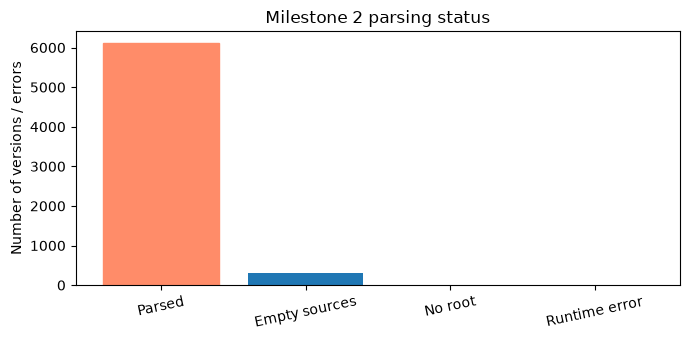

In [2]:
if ready:
    measurements = [
      ('Publications selected', stats.get('assigned_count_this_run', 0)),
      ('Publications processed', counts.get('processed', 0)),
      ('Unexpected parser errors', counts.get('errors', 0)),
      ('Total versions selected', counts.get('versions_expected', 0)),
      ('Versions parsed', counts.get('versions_parsed', 0)),
      ('No TeX/source versions (empty records)', counts.get('versions_empty', 0)),
      ('Versions with no detected document root', counts.get('versions_no_root', 0)),
      ('Parsed/version coverage', round(counts.get('versions_parsed',0) / counts.get('versions_expected',1) * 100, 2) if counts.get('versions_expected') else 0),
    ]
    display(pd.DataFrame(measurements, columns=['Measure', 'Value']))
    fig, ax = plt.subplots(figsize=(7,3.5))
    names=['Parsed', 'Empty sources', 'No root', 'Runtime error']
    vals=[counts.get('versions_parsed',0),counts.get('versions_empty',0),
          counts.get('versions_no_root',0),counts.get('errors',0)]
    ax.bar(names,vals)
    ax.patches[0].set_color('#FF8C69')
    ax.set_ylabel('Number of versions / errors')
    ax.set_title('Milestone 2 parsing status')
    ax.tick_params(axis='x',rotation=12)
    plt.tight_layout();plt.show()


## 4. Before-and-after de-duplication

An element is identified by cleaned semantic content and type *within each publication* (not across unrelated publications). References are deduplicated across that publication’s versions, including metadata field union and key remapping. These counts are measurements from the local parser run; they do not imply that textual identity guarantees semantic identity.


,Type,Before,After,Removed,Reduction (%)
0,Parsed elements,2834259,2280571,553688,19.54
1,BibTeX entries,483550,383892,99658,20.61


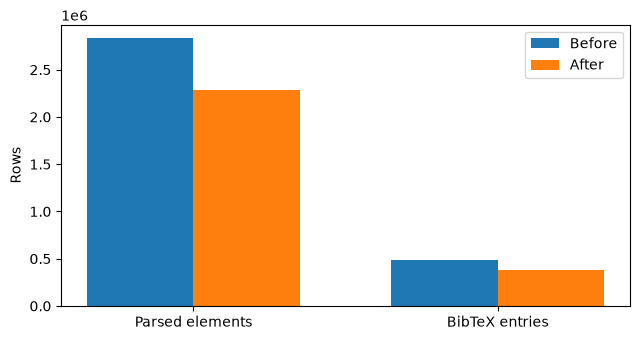

In [3]:
if ready:
    comp = pd.DataFrame([
      {'Type':'Parsed elements', 'Before':counts.get('content_before_dedup',0), 'After':counts.get('content_after_dedup',0)},
      {'Type':'BibTeX entries', 'Before':counts.get('references_before_dedup',0), 'After':counts.get('references_after_dedup',0)},
    ])
    comp['Removed'] = comp['Before']-comp['After']
    comp['Reduction (%)'] = (comp['Removed'] / comp['Before'].where(comp['Before'] != 0, float('nan')) * 100).round(2)
    display(comp)
    fig,ax=plt.subplots(figsize=(6.5,3.5))
    x=range(len(comp));width=.35
    ax.bar([v-width/2 for v in x],comp['Before'],width,label='Before')
    ax.bar([v+width/2 for v in x],comp['After'],width,label='After')
    ax.set_xticks(list(x),comp['Type'])
    ax.set_ylabel('Rows');ax.legend();plt.tight_layout();plt.show()


## 5. Milestone 2 performance benchmark

This section reports the saved full-range parsing measurements in
`report_data/Mile2_Colab_CPU_Benchmark.json`: 5,000 publications,
6,417 versions, wall time, process RSS samples, and final output size.

The JSON records 5,000 fresh parses and was transcribed from Colab
output, but it does not include raw runtime metadata or the original
execution log. Therefore, these are reported measurements; this file
alone does not independently verify the required Colab CPU-only
testbed. Preserve and cite the original Colab output if available.


### Reported Milestone 2 Results

,Metric,Measured Value
0,Publications,5000
1,Fresh parsed,5000
2,Cached count (if recorded),Not recorded
3,Testbed in saved JSON,Not recorded
4,Runtime errors,0
5,Versions expected,6417
6,Versions parsed,6105
7,Versions empty,312
8,Versions no root,0
9,Wall time (seconds),1047.815


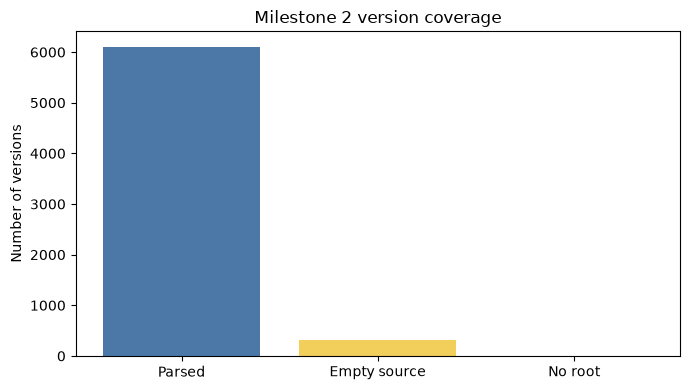

**Coverage and value consistency checks passed. Testbed provenance is shown only when recorded in the source JSON.**

In [4]:

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

path = Path("report_data/Mile2_Colab_CPU_Benchmark.json")

bench = json.loads(path.read_text(encoding="utf-8"))
m = bench["metrics"]

processed = int(m["processed"])
fresh = int(m["fresh_parsed"])
cached = m.get("cached")
parsed = int(m["versions_parsed"])
empty = int(m["versions_empty"])
no_root = int(m["versions_no_root"])

peak_ram = bench.get("peak_ram_mib")
if peak_ram is None:
    peak_ram = bench["peak_ram_bytes"] / 1024**2

disk = bench.get("output_disk_mib")
if disk is None:
    disk = bench["output_disk_bytes"] / 1024**2

assert processed == 5000
assert fresh == 5000
assert parsed == 6105
assert empty == 312
assert no_root == 0
assert parsed + empty + no_root == m["versions_expected"]

table = pd.DataFrame([
    ("Publications", processed),
    ("Fresh parsed", fresh),
    ("Cached count (if recorded)", cached if cached is not None else "Not recorded"),
    ("Testbed in saved JSON", bench.get("testbed", "Not recorded")),
    ("Runtime errors", m.get("errors", 0)),
    ("Versions expected", m["versions_expected"]),
    ("Versions parsed", parsed),
    ("Versions empty", empty),
    ("Versions no root", no_root),
    ("Wall time (seconds)", bench["wall_seconds"]),
    ("Average seconds / paper", bench["avg_seconds_per_publication"]),
    ("Peak RAM (MiB)", round(peak_ram, 2)),
    ("Output disk (MiB)", round(disk, 2))
], columns=["Metric", "Measured Value"])

display(Markdown("### Reported Milestone 2 Results"))
display(table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Parsed", "Empty source", "No root"], [parsed, empty, no_root], color=["#4c78a8", "#f2cf5b", "#e45756"])
ax.set_ylabel("Number of versions")
ax.set_title("Milestone 2 version coverage")
plt.tight_layout()
plt.show()

if "transcri" in (
    bench.get("source", "") + bench.get("description", "")
).lower():
    display(Markdown(
        "*Note: measurements were transcribed from the Colab "
        "output; use the original summary.json for exact values.*"
    ))

display(Markdown("**Coverage and value consistency checks passed. Testbed provenance is shown only when recorded in the source JSON.**"))


## 6. Reproducibility and limitations

Re-run the parser with `python -m src.milestone2.cli --output data --force --report ../report_repo` from `source_repo`; omit `--force` to resume from existing per-paper checkpoints. Test first with `--max-papers 20`. Source inputs and all Mile 1 modules remain read-only. The outputs include `data/milestone2/{tables,records_data,summary.json,status.csv}`. Submit source-only repositories publicly; large crawled/parsed corpora remain local working data and are not included in this report repository.

**To validate parser accuracy beyond unit tests:** manually inspect a stratified sample with `no_root` warnings, nested macro-rich LaTeX, multiple roots, inline BibTeX entries, and papers with multiple versions; compare against actual rendered document structure. Manual checking was not substituted for automatic statistics here.


## 7. Final Dataset Validation

This section validates the final Milestone 2 dataset
using the synchronized results generated by the parser.

Validation confirms that all 5,000 assigned publications were processed,
covering 6,417 versions in total.
The 312 source-free versions remain explicitly recorded
as empty rather than being treated as parser failures.
All 6,417 versions are accounted for in the final dataset.


In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown

s = json.loads(
    Path("report_data/milestone2_summary.json").read_text(
        encoding="utf-8"
    )
)
m = s["metrics"]

validation = pd.DataFrame([
    ("Publications", m["processed"]),
    ("Total versions", m["versions_expected"]),
    ("Successfully parsed", m["versions_parsed"]),
    ("Empty source versions", m["versions_empty"]),
    ("No detected root", m["versions_no_root"]),
], columns=["Metric", "Value"])

display(validation)

assert (
    m["versions_parsed"]
    + m["versions_empty"]
    + m["versions_no_root"]
) == m["versions_expected"]

display(Markdown(
    "**Validation passed:** All 6,417 versions are accounted for."
))


,Metric,Value
0,Publications,5000
1,Total versions,6417
2,Successfully parsed,6105
3,Empty source versions,312
4,No detected root,0


**Validation passed:** All 6,417 versions are accounted for.